## Question 1

##### 1.1

In [1]:
# Load libraries
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jessb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
#load the data
df = pd.read_json(r"C:\Users\jessb\OneDrive\Desktop\University\University\CTI\Honours\Semester 2\ITNPA4\Assignment\Datasets\research_abstracts.json")

In [3]:
#Explore the data
print(df.head())
print(df.shape)
print(df.info())

#print column names
print(df.columns)

print("Missing values:\n", df.isnull().sum())
print("Duplicate Abstracts:\n", df.duplicated(subset='Abstract').sum())
print("Class Counts:\n", df['Label'].value_counts())

                          DOI  \
0        10.1155/2021/1071145   
1  10.1007/s43546-022-00384-2   
2            10.1002/for.2667   
3  10.1007/s42973-021-00091-x   
4   10.1007/s40258-012-0003-z   

                                            Abstract      Label  
0  Forward-looking forecasting of the inflation r...         ai  
1  Our study examined the disaggregation of infla...         ai  
2  This paper develops a dynamic factor model tha...  classical  
3  In this paper, I use a simple SIR Macro model ...  classical  
4  BackgroundGame theory is useful for identifyin...  classical  
(1138, 3)
<class 'pandas.DataFrame'>
Index: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   DOI       1134 non-null   str  
 1   Abstract  1138 non-null   str  
 2   Label     1138 non-null   str  
dtypes: str(3)
memory usage: 35.6 KB
None
Index(['DOI', 'Abstract', 'Label'], dtype='str')
Missing values:
 DOI         

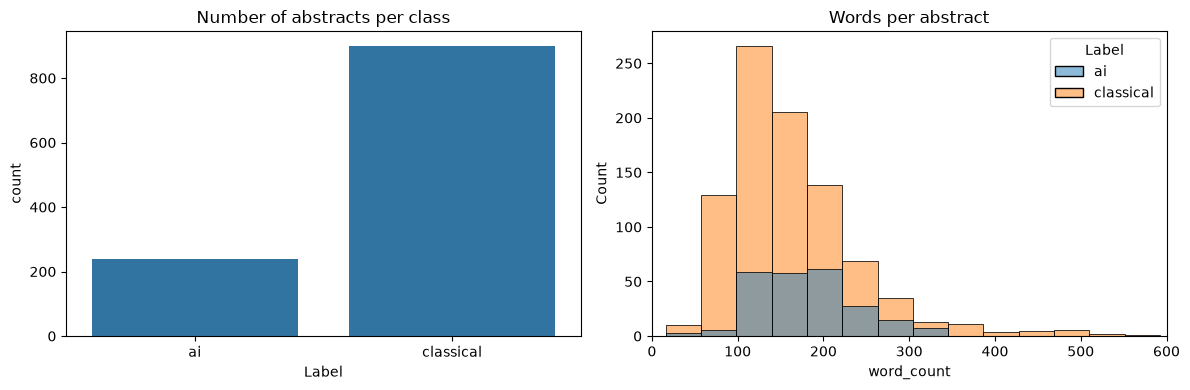

In [4]:
#plot visual
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
sns.countplot(data=df, x="Label", ax=axes[0])
axes[0].set_title("Number of abstracts per class")
 
df["word_count"] = df["Abstract"].apply(lambda x: len(str(x).split()))
sns.histplot(data=df, x="word_count", hue="Label", bins=50, ax=axes[1])
axes[1].set_xlim(0, 600)
axes[1].set_title("Words per abstract")
plt.tight_layout()
plt.show()

In [5]:
#assessing noise in abstracts
for text in df["Abstract"].sample(3, random_state=1):
    print(text[:300], "...\n")

Abstract This chapter is concerned with forecasting and prediction based on the UK model. It elaborates on the notion of probability forecasting, which provides a useful means of conveying the uncertainties surrounding forecasts obtained from the model. It illustrates the usefulness of probability f ...

One of the problems experienced by micro, small, and medium enterprises (MSMEs) during this pandemic is that most MSME actors do not understand plan-making during a crisis. This situation was exacerbated by erratic commodity prices, which resulted in several MSME players choosing to temporarily clos ...

This study evaluates oil price forecasts based on their economic significance for macroeconomic predictions. More specifically, we first use the current state-of-the-art frameworks to forecast monthly oil prices and subsequently we use these forecasts, as oil price assumptions, to predict eurozone a ...



In [6]:
#most common first words
df["Abstract"].str.split().str[0].value_counts().head(10)

Abstract
This         266
The          143
We           132
In           101
A             35
Abstract      28
Inflation     20
Using         18
Purpose       12
I              9
Name: count, dtype: int64

In [7]:
#most commong last 4 words
df["Abstract"].str.split().str[-4:].str.join(" ").value_counts().head(8)

Abstract
Wiley & Sons, Ltd.                    15
additional charge at www.nber.org.     5
predictions of the model.              5
in the euro area.                      3
The data confirm this.                 3
forecasts of the IMF.                  3
researchers and policy makers.         3
point and density predictions.         2
Name: count, dtype: int64

In [8]:
#print full example
for word in ["Wiley", "nber"]:
    example = df.loc[df["Abstract"].str.contains(word), "Abstract"].iloc[0]
    print("..." + example[-200:], "\n")

...ves more accurate forecasts than simple equal‐weighted averaging. This superior performance is consistent across subsamples and a number of inflation measures. Copyright © 2008 John Wiley & Sons, Ltd. 

...dictions of “anchored” expectations.Institutional subscribers to the NBER working paper series, and residents of developing countries may download this paper without additional charge at www.nber.org. 



In [9]:
#characters not a letter or space
from collections import Counter

other_chars = Counter(c for text in df["Abstract"] for c in text
                      if not (c.isascii() and (c.isalpha() or c.isspace())))
print(other_chars.most_common(30))

[('.', 9053), (',', 8546), ('-', 3165), ('0', 2202), ('1', 1857), (')', 1628), ('(', 1617), ('2', 1532), ('9', 1171), ('8', 521), ("'", 488), ('5', 484), (':', 429), ('3', 419), ('7', 392), ('4', 378), ('’', 371), ('6', 326), ('%', 281), ('‐', 277), (';', 254), ('/', 191), ('–', 188), ('"', 167), ('“', 125), ('”', 123), ('—', 87), ('é', 82), ('?', 71), ('\xa0', 66)]


In [10]:
#noise patterns
noise_patterns = {
    "Copyright notices": r"[Cc]opyright|©",
    "NBER notices": r"Institutional subscribers",
    "URLs": r"http\S+|www\S+",
    "Numbers": r"\d+",
    "'Abstract'/'Purpose' heading at the start": r"^\s*(?:Abstract|Purpose)",
    "Non-English characters (’ – é)": r"[^\x00-\x7f]",
    "Punctuation / symbols": r"[^\w\s]",
}

In [11]:
#noise countss
noise_counts = {}
for name, pattern in noise_patterns.items():
    matches = df["Abstract"].str.contains(pattern, regex=True)
    noise_counts[name] = matches.sum()
    print(f"{name}: {matches.sum()} abstracts")


Copyright notices: 16 abstracts
NBER notices: 5 abstracts
URLs: 7 abstracts
Numbers: 689 abstracts
'Abstract'/'Purpose' heading at the start: 47 abstracts
Non-English characters (’ – é): 443 abstracts
Punctuation / symbols: 1138 abstracts


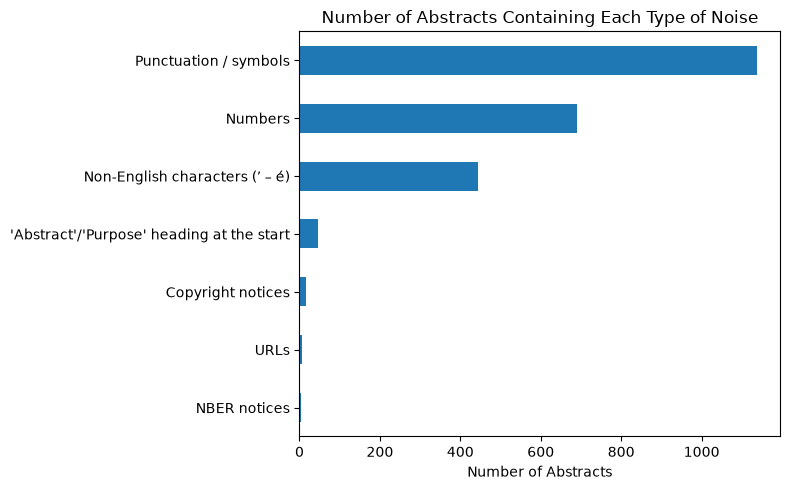

In [12]:
#visual of type of noise
pd.Series(noise_counts).sort_values().plot(kind="barh", figsize=(8, 5), title="Number of Abstracts Containing Each Type of Noise")
plt.xlabel("Number of Abstracts")
plt.tight_layout()
plt.show()

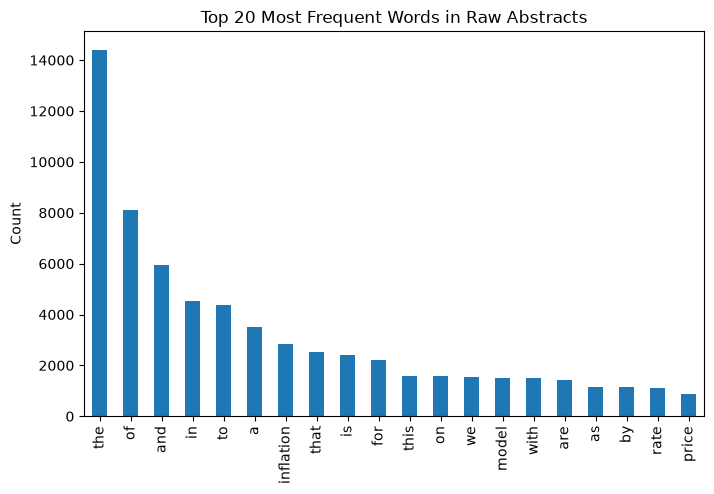

Percent of Words that are NLTK Stopwords: 38.7%


In [13]:
#most frequent words in raw text
raw_words = " ".join(df["Abstract"]).lower()
raw_words = re.findall(r"[a-z]+", raw_words)
top_raw = pd.Series(raw_words).value_counts().head(20)

#visual
top_raw.plot(kind="bar", figsize=(8, 5), title="Top 20 Most Frequent Words in Raw Abstracts")
plt.ylabel("Count")
plt.show()

stop_words = set(stopwords.words("english"))
print("Percent of Words that are NLTK Stopwords: %.1f%%" %
      (100 * sum(w in stop_words for w in raw_words) / len(raw_words)))

In [14]:
#remove duplicated and missing abstracts
df = df.drop_duplicates(subset="Abstract").dropna(subset=["Abstract"]).reset_index(drop=True)
print("Number of rows after removing duplicates:", len(df))

Number of rows after removing duplicates: 1125


In [15]:
# NLTK stopwords and specific words found
stop_words = set(stopwords.words("english"))
stop_words.update(["inflation", "paper", "also", "abstract", "purpose"])
lemmatizer = WordNetLemmatizer()

In [16]:
#cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"copyright.*|©.*", " ", text)
    text = re.sub(r"institutional subscribers.*", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 1]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return " ".join(tokens)
 
 
df["clean_abstract"] = df["Abstract"].apply(clean_text)

In [17]:
#checking that noise is gone
for name, pattern in noise_patterns.items():
    matches = df["clean_abstract"].str.contains(pattern, regex=True)
    noise_counts[name] = matches.sum()
    print(f"{name}: {matches.sum()} abstracts")


Copyright notices: 0 abstracts
NBER notices: 0 abstracts
URLs: 0 abstracts
Numbers: 0 abstracts
'Abstract'/'Purpose' heading at the start: 0 abstracts
Non-English characters (’ – é): 0 abstracts
Punctuation / symbols: 0 abstracts


In [18]:
#most common words after cleaning
for label in df["Label"].unique():
    words = " ".join(df[df["Label"] == label]["clean_abstract"]).split()
    print(label, pd.Series(words).value_counts().head(10).to_dict(), "\n")


ai {'model': 541, 'prediction': 363, 'price': 361, 'data': 294, 'rate': 289, 'forecast': 243, 'method': 230, 'result': 178, 'economic': 174, 'using': 171} 

classical {'model': 1702, 'rate': 1252, 'prediction': 1045, 'price': 940, 'forecast': 692, 'policy': 619, 'data': 548, 'economic': 503, 'monetary': 492, 'time': 488} 



##### 1.2

In [19]:
#save the cleaned data to a new CSV file
df[["DOI", "Label", "clean_abstract"]].to_csv("cleaned_abstracts.csv", index=False)

In [20]:
#df columns
print("Unique DOIs:", df["DOI"].nunique(), "out of", len(df), "rows")
print("Unique Labels:", df["Label"].unique())
df[["DOI","Abstract", "Label"]].head(3)

Unique DOIs: 1123 out of 1125 rows
Unique Labels: <StringArray>
['ai', 'classical']
Length: 2, dtype: str


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical


In [21]:
#encode the target
le = LabelEncoder()
df["label_encoded"] = le.fit_transform(df["Label"])
print(dict(zip(le.classes_, le.transform(le.classes_))))

{'ai': np.int64(0), 'classical': np.int64(1)}


In [22]:
#TF-IDF features from cleaned abstracts
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df["clean_abstract"])
y = df["label_encoded"]
print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (1125, 5000)


In [23]:
#Chi-square test
selector = SelectKBest(chi2, k=20)
selector.fit(X_tfidf, y)

chi2_scores = pd.DataFrame({"feature": tfidf.get_feature_names_out(), "chi2_score": selector.scores_})
top20 = chi2_scores.sort_values("chi2_score", ascending=False).head(20)

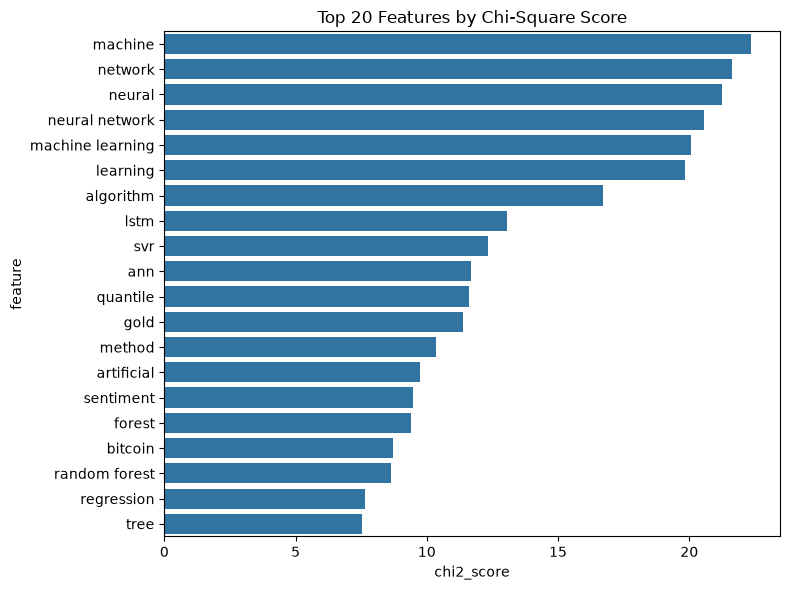

In [24]:
#chi visual
plt.figure(figsize=(8, 6))
sns.barplot(data=top20, x="chi2_score", y="feature")
plt.title("Top 20 Features by Chi-Square Score")
plt.tight_layout()
plt.show()

##### 1.3

In [25]:
#baseline model training
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_abstract"], y, test_size=0.2, random_state=42, stratify=y)

# Fit TF-IDF on the training data only
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
 
baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_tfidf, y_train)
 
y_train_pred = baseline.predict(X_train_tfidf)
y_test_pred = baseline.predict(X_test_tfidf)


In [26]:
print("Training accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("Test accuracy:    ", round(accuracy_score(y_test, y_test_pred), 4))
 
print("\nClassification report (test set):")
print(classification_report(y_test, y_test_pred, target_names=le.classes_))

Training accuracy: 0.8956
Test accuracy:     0.8356

Classification report (test set):
              precision    recall  f1-score   support

          ai       1.00      0.21      0.35        47
   classical       0.83      1.00      0.91       178

    accuracy                           0.84       225
   macro avg       0.91      0.61      0.63       225
weighted avg       0.86      0.84      0.79       225



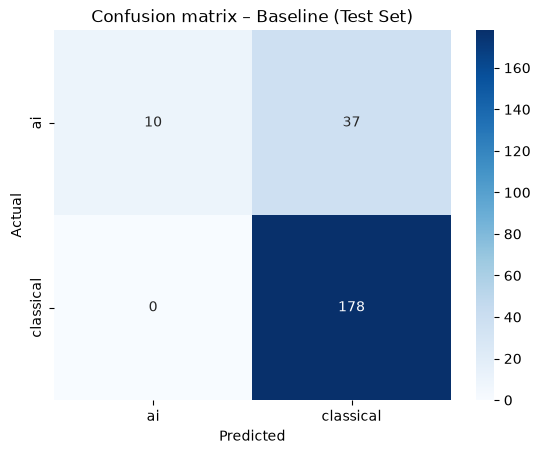

In [27]:
#confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix – Baseline (Test Set)")
plt.show()

In [28]:
#5 fols cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(LogisticRegression(max_iter=1000, random_state=42), X_train_tfidf, y_train, cv=cv, scoring="f1_macro")
print("CV macro-F1 per fold:", cv_scores.round(3))
print("Mean CV macro-F1: %.3f (+/- %.3f)" % (cv_scores.mean(), cv_scores.std()))

CV macro-F1 per fold: [0.67  0.569 0.698 0.681 0.581]
Mean CV macro-F1: 0.640 (+/- 0.054)


In [29]:
#learning curve
train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=1000, random_state=42), X_train_tfidf, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.1, 1.0, 8))

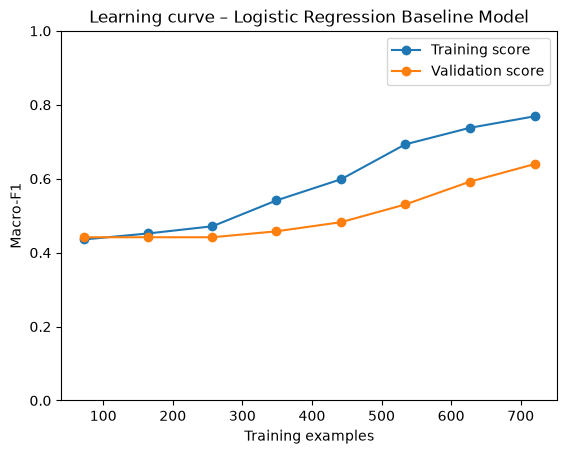

In [30]:
#Visual learning curve
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Training score")
plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="Validation score")
plt.xlabel("Training examples")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.title("Learning curve – Logistic Regression Baseline Model")
plt.legend()
plt.show()